In [53]:
# Step 1: Import necessary libraries
# numpy for numerical calculations, matplotlib for plotting graphs
import math
import numpy as np
import matplotlib.pyplot as plt
%matplotlib inline

In [54]:
# Step 2: Define a simple quadratic function f(x)
def f(x):
  return 3 * x ** 2 - 4 * x + 5

In [55]:
# Step 3: Test the function with a single scalar value input (x = 3.0)
f(3.0)

20.0

In [56]:
# Step 4: Generate a range of x values from -5 to 5 and calculate their corresponding y values
xs = np.arange(-5, 5, 0.25)
ys = f(xs)
ys

array([100.    ,  91.6875,  83.75  ,  76.1875,  69.    ,  62.1875,
        55.75  ,  49.6875,  44.    ,  38.6875,  33.75  ,  29.1875,
        25.    ,  21.1875,  17.75  ,  14.6875,  12.    ,   9.6875,
         7.75  ,   6.1875,   5.    ,   4.1875,   3.75  ,   3.6875,
         4.    ,   4.6875,   5.75  ,   7.1875,   9.    ,  11.1875,
        13.75  ,  16.6875,  20.    ,  23.6875,  27.75  ,  32.1875,
        37.    ,  42.1875,  47.75  ,  53.6875])

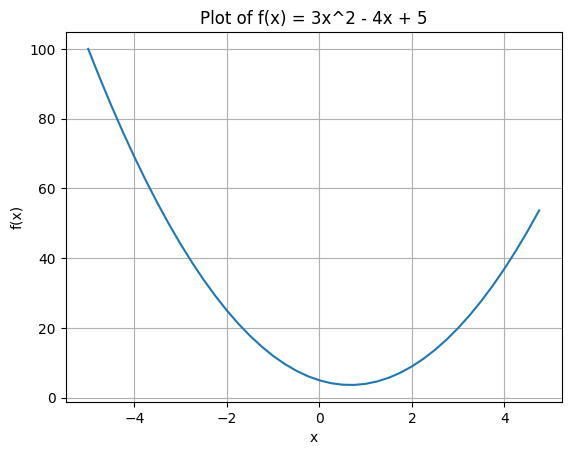

In [57]:
# Plotting the function f(x)
# We use the generated xs and calculated ys to plot the continuous curve
plt.plot(xs, ys)
plt.title('Plot of f(x) = 3x^2 - 4x + 5')
plt.xlabel('x')
plt.ylabel('f(x)')
plt.grid(True)
plt.show()

In [58]:
# Taking the derivative of the function
# definition -> lim (h -> 0) (f(x + h) - f(x)) / h

h = 0.0000000001
x = 2 / 3
(f(x + h) - f(x)) / h


0.0

In [59]:
# Step 5: Create simple variables and perform a basic arithmetic operation (d = a * b + c)
a = 2.0
b = -3.0
c = 10.0
d = a * b + c
print(d)

4.0


In [ ]:
# derivative of above cell with respect to a

h = 0.0001
a = 2.0
b = -3.0
c = 10.0
d1 = a * b + c

a += h
d2 = a * b + c

print('slope', (d2 - d1) / h)

# We can do same with b and c as well




slope -3.000000000010772


In [100]:
# Step 6: Build a custom 'Value' class to keep track of the operations and children
# This serves as the foundation for building an autograd engine (backpropagation)


# We need to calculate the derevitive of L (loss function) wrt to other variables

class Value:
  def __init__(self, data, _children=(), _op='', label = ''):
    self.data = data
    self._prev = set(_children)
    self._backward = lambda: None
    # At init, we assume it does not effect output
    self.grad = 0.0
    self._op = _op
    self.label = label

  def __repr__(self):
    return f'Value(data={self.data})'

  def __sub__(self, other):
    return self + (-other)

  def __neg__(self):
    return self * -1

  def __add__(self, other):
    other = other if isinstance(other, Value) else Value(other)
    out = Value(self.data + other.data, (self, other), '+')

    def _backward():
      self.grad += 1.0 * out.grad
      other.grad += 1.0 * out.grad
    out._backward = _backward
    return out

  def __radd__(self, other):
    return self + other

  def __mul__(self, other):
    other = other if isinstance(other, Value) else Value(other)
    out = Value(self.data * other.data, (self, other), '*')

    def _backward():
      self.grad += (other.data * out.grad)
      other.grad += (self.data * out.grad)
    out._backward = _backward
    return out

  def __rmul__(self, other):
    return self * other

  def __pow__(self, other):
    assert isinstance(other, (int, float)), "only supporting int/float powers for now"
    out = Value(self.data ** other, (self,), f'**{other}')

    def _backward():
      self.grad += (other * (self.data ** (other - 1)) * out.grad)
    out._backward = _backward
    return out

  def exp(self):
    return Value(math.exp(self.data), (self,), 'exp')

  def tanh(self):
    n = self.data
    t = (math.exp(2*n) - 1)/(math.exp(2*n) + 1)
    out = Value(t, (self, ), 'tanh')

    def _backward():
      self.grad += (1 - t ** 2) * out.grad
    out._backward = _backward
    return out

  def backward(self):
    topo = []
    visited = set()

    def build_topo(v):
      if v not in visited:
        visited.add(v)
        for child in v._prev:
          build_topo(child)
        topo.append(v)

    build_topo(self)
    self.grad = 1.0

    for node in reversed(topo):
      node._backward()

a = Value(2.0, label='a')
b = Value(-3.0, label='b')
c = Value(10.0, label='c')
e = a*b; e.label = 'e'
d = e + c; d.label = 'd'
f = Value(-2.0, label='f')
L = d * f; L.label = 'L'
L

Value(data=-8.0)

In [61]:
from graphviz import Digraph

def trace(root):
  # builds a set of all nodes and edges in a graph
  nodes, edges = set(), set()
  def build(v):
    if v not in nodes:
      nodes.add(v)
      for child in v._prev:
        edges.add((child, v))
        build(child)
  build(root)
  return nodes, edges

def draw_dot(root):
  dot = Digraph(format='svg', graph_attr={'rankdir': 'LR'}) # LR = left to right

  nodes, edges = trace(root)
  for n in nodes:
    uid = str(id(n))
    # for any value in the graph, create a rectangular ('record') node for it
    dot.node(name = uid, label = "{ %s | data %.4f | grad %.4f }" % (n.label, n.data, n.grad), shape='record')
    if n._op:
      # if this value is a result of some operation, create an op node for it
      dot.node(name = uid + n._op, label = n._op)
      # and connect this node to it
      dot.edge(uid + n._op, uid)

  for n1, n2 in edges:
    # connect n1 to the op node of n2
    dot.edge(str(id(n1)), str(id(n2)) + n2._op)

  return dot



In [ ]:
# Backpropagation of neuron

In [62]:
# Neuron value (inputs + weights)

# inputs x1, x2

x1 = Value(2.0, label='x1')
x2 = Value(0.0, label='x2')

# weights w1, w2
w1 = Value(-3.0, label='w1')
w2 = Value(1.0, label='w2')

# bias of a neuron
b = Value(6.8813, label='b')

# x1w1 + x2w2 + b
x1w1 = x1 * w1; x1w1.label = 'x1w1'
x2w2 = x2 * w2; x2w2.label = 'x2w2'

x1w1x2w2 = x1w1 + x2w2; x1w1x2w2.label = 'x1w1 + x2w2'
n = x1w1x2w2 + b; n.label = 'n'

o = n.tanh()
o.grad = 1.0
o.label = 'o'



In [ ]:
o.backward()

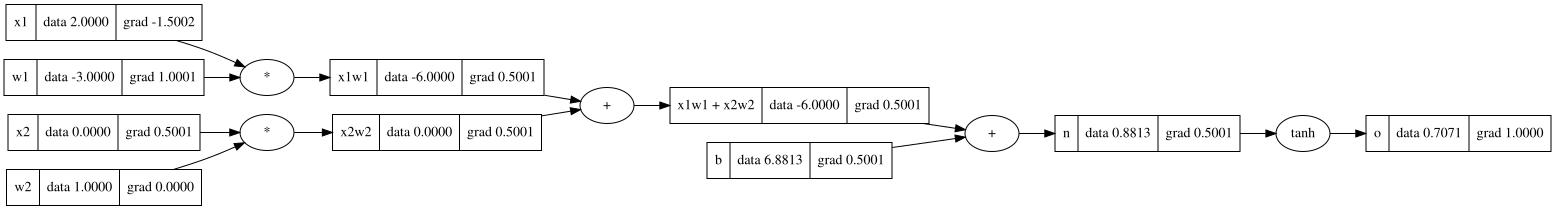

In [ ]:
draw_dot(o)

In [ ]:
# a + 1 not gonna work because 1 is int and not Value, so fix is to define other as Value
a = Value(2.0)
a + 1

# Same for mult, a * 2 -> not defined, but even if we define it 2 * a is not define, so we use rmult

Value(data=3.0)

In [64]:
import torch

In [65]:
x1 = torch.Tensor([2.0]).double()
x1.requires_grad = True
x2 = torch.Tensor([0.0]).double()
x2.requires_grad = True

w1 = torch.Tensor([-3.0]).double()
w1.requires_grad = True
w2 = torch.Tensor([1.0]).double()
w2.requires_grad = True

b = torch.Tensor([6.8813735870195432]).double()

n = x1 * w1 + x2 * w2 + b

o = torch.tanh(n)

print(o.data.item())
o.backward()

print('---')
print('x2', x2.grad.item())
print('w2', w2.grad.item())
print('x1', x1.grad.item())
print('w1', w1.grad.item())

0.7071066904050358
---
x2 0.5000001283844369
w2 0.0
x1 -1.5000003851533106
w1 1.0000002567688737


In [66]:
o

tensor([0.7071], dtype=torch.float64, grad_fn=<TanhBackward0>)

In [104]:
# Simple neuron using pytorch
import random

class Neuron:
  def __init__(self, nin):
    """
    nin -> number of inputs
    self.w -> weights for each input
    self.b -> bias for the neuron

    """
    self.w = [Value(random.uniform(-1,1)) for _ in range(nin)]
    self.b = Value(random.uniform(-1,1))

  def __call__(self, x):
    # w * x + b
    # By using self.b as the start value for sum, we avoid adding Value to a raw integer/float 0
    act = sum((wi * xi for wi, xi in zip(self.w, x)), self.b)
    out = act.tanh()
    return out

  def parameters(self):
    return self.w + [self.b]

class Layer:

  def __init__(self, nin, nout):
    """
    nin -> number of inputs
    nout -> number of neurons in the layer
    """
    self.neurons = [Neuron(nin) for _ in range(nout)]

  def __call__(self, x):
    outs = [n(x) for n in self.neurons]
    return outs[0] if len(outs) == 1 else outs

  def parameters(self):
    return [p for neuron in self.neurons for p in neuron.parameters()]

class MLP:
  def __init__(self, nin, nouts):
    """
    nin -> number of inputs
    nouts -> list of number of neurons in each layer
    """
    # eg : 2, [2, 3, 4]
    sz = [nin] + nouts
    # sz : [2, 2, 3, 4]
    # layers = [l1(2, 2), l2(2, 3), l3(3, 4)]
    self.layers = [Layer(sz[i], sz[i+1]) for i in range(len(nouts))]

  def __call__(self, x):
    for layer in self.layers:
      x = layer(x)
    return x

  def parameters(self):
    return [p for layer in self.layers for p in layer.parameters()]


x = [2.0, 3.0, -1.0]
n = MLP(3, [4, 4, 1])
n(x)

Value(data=0.09126901566541941)

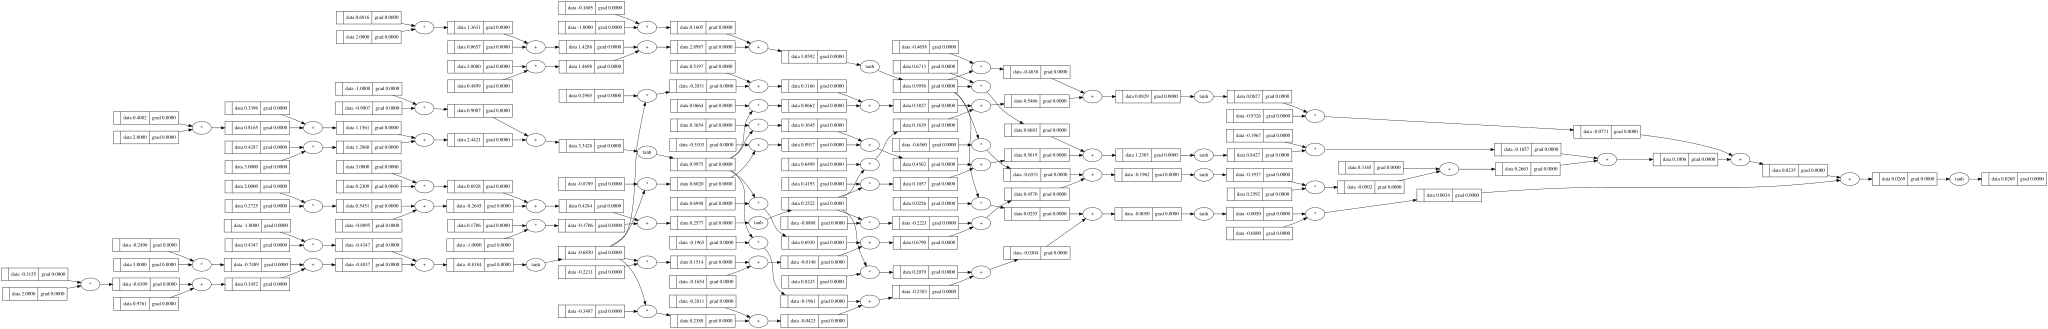

In [86]:
draw_dot(n(x)[0])

In [202]:
# Defining the desired input and output

xs = [
    [2.0, 3.0, -1.0],
    [3.0, -1.0, 0.5],
    [0.5, 1.0, 1.0],
    [1.0, 1.0, -1.0]
]

ys = [1.0, -1.0, -1.0, 1.0]

# Re-instantiate the model so it uses the updated MLP class that unpacks single outputs
n = MLP(3, [4, 4, 1])


In [196]:
# Checking the neurons at 0 layer
n.layers[0].parameters()


[Value(data=0.9699106421392338),
 Value(data=-0.5728623954378329),
 Value(data=0.393204937428151),
 Value(data=0.14870893868810486),
 Value(data=0.8734917830951727),
 Value(data=-0.6749569213168694),
 Value(data=0.014126762302548501),
 Value(data=0.49153633937585384),
 Value(data=-0.21602173912723766),
 Value(data=0.4934401604604146),
 Value(data=-0.8700970253462592),
 Value(data=-0.10456974442753286),
 Value(data=-0.5778904069415305),
 Value(data=0.5946879633404318),
 Value(data=0.4167194279707691),
 Value(data=-0.5700700692162353)]

In [1]:
for k in range(20):
  ypred = [n(x) for x in xs]
  loss = sum((yout - ygt) ** 2 for ygt, yout in zip(ys, ypred))

  for p in n.parameters():
    p.grad = 0.0

  loss.backward()

  # Gradient descent step (using -= to update, and a slightly larger step rate)
  for p in n.parameters():
    p.data -= 0.05 * p.grad

  print(k, loss.data)

NameError: name 'xs' is not defined